# Análise exploratória — Telco Customer Churn

Objetivo: entender a qualidade dos dados e quais variáveis se relacionam com o cancelamento (`Churn Value`).
Os dados são analisados crus, como saem de `load_raw()`. Os problemas encontrados aqui viram regras de limpeza em `src/telco_churn/data.py`.

## 0. Setup

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

from telco_churn.data import load_raw

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
cores = {0: "#257de0", 1: "#f47230"}  # 0 = ficou, 1 = cancelou

df = load_raw()

## 1. Visão geral

In [3]:
df.shape

(7043, 33)

In [4]:
df.head()

,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Multiple Lines,Internet Service,Online Security,Online Backup,Device Protection,Tech Support,Streaming TV,Streaming Movies,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,No,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,No,No,Yes,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,No,No,Yes,8,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,No,Yes,Yes,28,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,No,No,Yes,49,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [38]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 33 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   CustomerID         7043 non-null   str    
 1   Count              7043 non-null   int64  
 2   Country            7043 non-null   str    
 3   State              7043 non-null   str    
 4   City               7043 non-null   str    
 5   Zip Code           7043 non-null   int64  
 6   Lat Long           7043 non-null   str    
 7   Latitude           7043 non-null   float64
 8   Longitude          7043 non-null   float64
 9   Gender             7043 non-null   str    
 10  Senior Citizen     7043 non-null   str    
 11  Partner            7043 non-null   str    
 12  Dependents         7043 non-null   str    
 13  Tenure Months      7043 non-null   int64  
 14  Phone Service      7043 non-null   str    
 15  Multiple Lines     7043 non-null   str    
 16  Internet Service   7043 non-null   

In [9]:
df.describe()

,Count,Zip Code,Latitude,Longitude,Tenure Months,Monthly Charges,Churn Value,Churn Score,CLTV
count,7043.0,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,1.0,93521.964646,36.282441,-119.798880,32.371149,64.761692,0.265370,58.699418,4400.295755
std,0.0,1865.794555,2.455723,2.157889,24.559481,30.090047,0.441561,21.525131,1183.057152
min,1.0,90001.000000,32.555828,-124.301372,0.000000,18.250000,0.000000,5.000000,2003.000000
25%,1.0,92102.000000,34.030915,-121.815412,9.000000,35.500000,0.000000,40.000000,3469.000000
50%,1.0,93552.000000,36.391777,-119.730885,29.000000,70.350000,0.000000,61.000000,4527.000000
75%,1.0,95351.000000,38.224869,-118.043237,55.000000,89.850000,1.000000,75.000000,5380.500000
max,1.0,96161.000000,41.962127,-114.192901,72.000000,118.750000,1.000000,100.000000,6500.000000


In [7]:
df.nunique().sort_values()

Count                   1
Country                 1
State                   1
Phone Service           2
Dependents              2
Partner                 2
Senior Citizen          2
Gender                  2
Churn Value             2
Paperless Billing       2
Churn Label             2
Multiple Lines          3
Internet Service        3
Online Backup           3
Online Security         3
Tech Support            3
Contract                3
Streaming Movies        3
Streaming TV            3
Device Protection       3
Payment Method          4
Churn Reason           20
Tenure Months          73
Churn Score            85
City                 1129
Monthly Charges      1585
Longitude            1651
Latitude             1652
Lat Long             1652
Zip Code             1652
CLTV                 3438
Total Charges        6531
CustomerID           7043
dtype: int64

**Conclusão:**
- 7.043 clientes × 33 colunas, um registro por cliente (`CustomerID` com 7.043 valores únicos).
- `Count`, `Country` e `State` têm um único valor: constantes, não carregam informação.
- `Total Charges` aparece com 6.531 valores distintos, mas não está entre as numéricas do `describe()`: é texto. Investigado na seção 2.
- Colunas de alta cardinalidade (`City`, `Zip Code`, `Lat Long`, `Latitude`, `Longitude`) analisadas na seção 6.

## 2. Qualidade dos dados

In [10]:
df.isnull().sum()[lambda s: s > 0]

Churn Reason    5174
dtype: int64

In [11]:
print("Linhas duplicadas:", df.duplicated().sum())
print("IDs duplicados:", df["CustomerID"].duplicated().sum())

Linhas duplicadas: 0
IDs duplicados: 0


Colunas de texto que deveriam ser numéricas: quantos valores **não** convertem para número?

In [12]:
for col in df.select_dtypes(exclude="number").columns:
    convertido = pd.to_numeric(df[col], errors="coerce")
    if convertido.notna().mean() > 0.9:
        print(col, "→ valores que não convertem:", convertido.isna().sum())

Total Charges → valores que não convertem: 11


Registros com problema na coluna encontrada acima:

In [13]:
col = "Total Charges"
invalidos = pd.to_numeric(df[col], errors="coerce").isna()
df.loc[invalidos, ["CustomerID", "Tenure Months", "Monthly Charges", "Total Charges", "Churn Value"]]

,CustomerID,Tenure Months,Monthly Charges,Total Charges,Churn Value
2234,4472-LVYGI,0,52.55,,0
2438,3115-CZMZD,0,20.25,,0
2568,5709-LVOEQ,0,80.85,,0
2667,4367-NUYAO,0,25.75,,0
2856,1371-DWPAZ,0,56.05,,0
4331,7644-OMVMY,0,19.85,,0
4687,3213-VVOLG,0,25.35,,0
5104,2520-SGTTA,0,20.00,,0
5719,2923-ARZLG,0,19.70,,0
6772,4075-WKNIU,0,73.35,,0


**Conclusão:**
- Sem linhas nem IDs duplicados.
- O único nulo é `Churn Reason` (5.174), que só existe para quem cancelou: esperado, e a coluna fica fora do modelo.
- `Total Charges` vem como texto porque 11 registros têm um espaço em branco (`' '`), não zero. Isso força a coluna para `object`; na conversão, esses valores viram `NaN`.
- Os 11 clientes têm `Tenure Months = 0`: acabaram de contratar e ainda não foram faturados.
- **Regra de limpeza:** converter `Total Charges` para número e, quando `Tenure Months = 0`, preencher com 0. Um `NaN` com tenure > 0 (se surgir) fica para o imputador do pipeline.

## 3. Alvo

In [14]:
df["Churn Value"].value_counts(normalize=True)

Churn Value
0    0.73463
1    0.26537
Name: proportion, dtype: float64

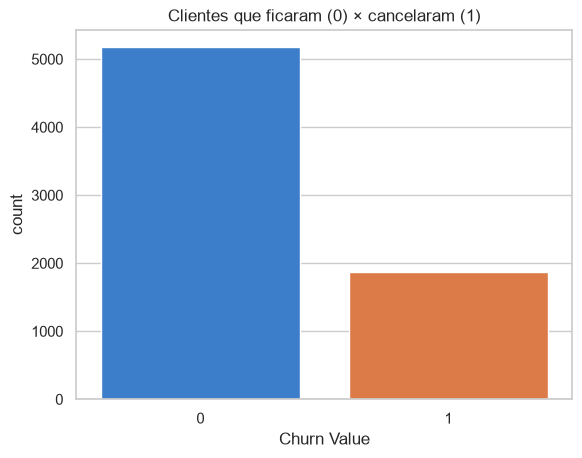

In [15]:
sns.countplot(data=df, x="Churn Value", hue="Churn Value", palette=cores, legend=False)
plt.title("Clientes que ficaram (0) × cancelaram (1)")
plt.show()

**Conclusão:**
- 26,5% dos clientes cancelaram: classes desbalanceadas (cerca de 1 churn para 3 que ficam).
- Acurácia não serve como métrica (um modelo que diz "ninguém cancela" acerta 73,5%). Usar AUC-ROC e recall/precision no top 20%, conforme o ML Canvas.
- Validação cruzada e split devem ser estratificados para preservar a proporção.

## 4. Variáveis numéricas
`Total Charges` é convertida numa cópia só para explorar; a correção oficial fica na limpeza.

In [16]:
numericas = ["Tenure Months", "Monthly Charges", "Total Charges"]

df_eda = df.copy()
df_eda["Total Charges"] = pd.to_numeric(df_eda["Total Charges"], errors="coerce")

df_eda[numericas].describe()

,Tenure Months,Monthly Charges,Total Charges
count,7043.000000,7043.000000,7032.000000
mean,32.371149,64.761692,2283.300441
std,24.559481,30.090047,2266.771362
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,401.450000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3794.737500
max,72.000000,118.750000,8684.800000


In [17]:
df_eda.groupby("Churn Value")[numericas].median()

,Tenure Months,Monthly Charges,Total Charges
Churn Value,,,
0,38.0,64.425,1683.60
1,10.0,79.650,703.55


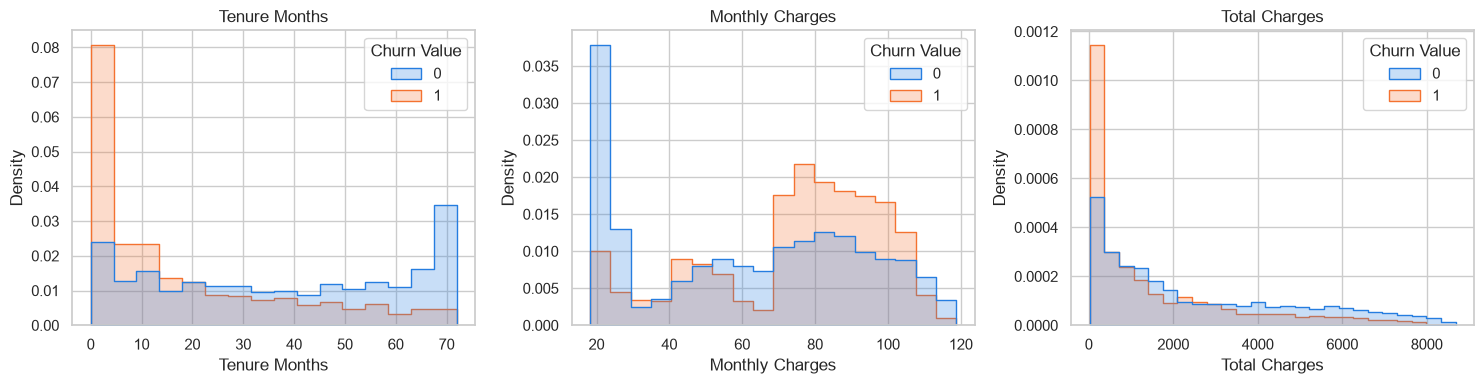

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, numericas):
    sns.histplot(data=df_eda, x=col, hue="Churn Value", stat="density", common_norm=False,
                 element="step", palette=cores, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

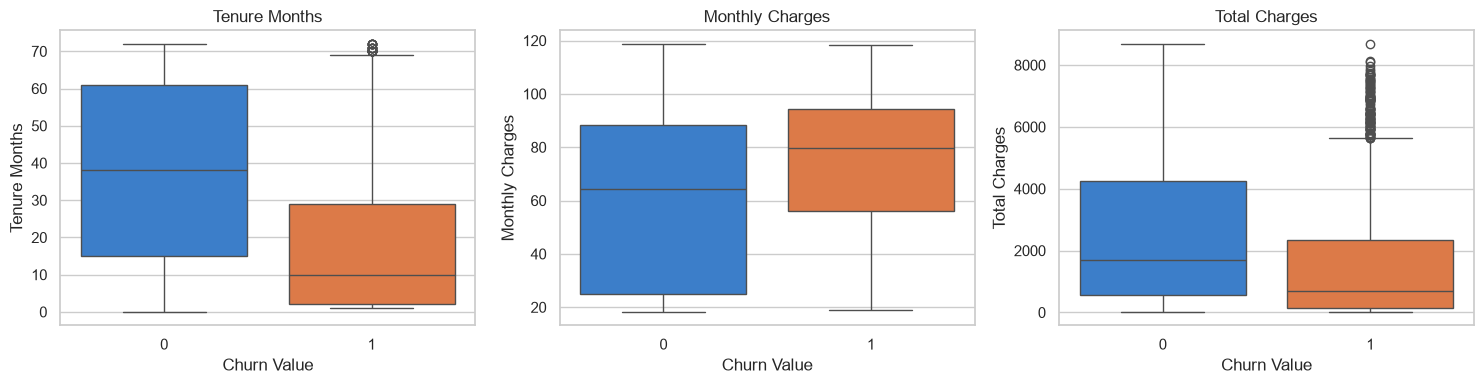

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, numericas):
    sns.boxplot(data=df_eda, x="Churn Value", y=col, hue="Churn Value", palette=cores,
                legend=False, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

Taxa de churn por faixa de tempo de contrato:

In [20]:
faixas = pd.cut(df_eda["Tenure Months"], bins=[-1, 6, 12, 24, 48, 72])
df_eda.groupby(faixas, observed=True)["Churn Value"].mean()

Tenure Months
(-1, 6]     0.529372
(6, 12]     0.358865
(12, 24]    0.287109
(24, 48]    0.203890
(48, 72]    0.095132
Name: Churn Value, dtype: float64

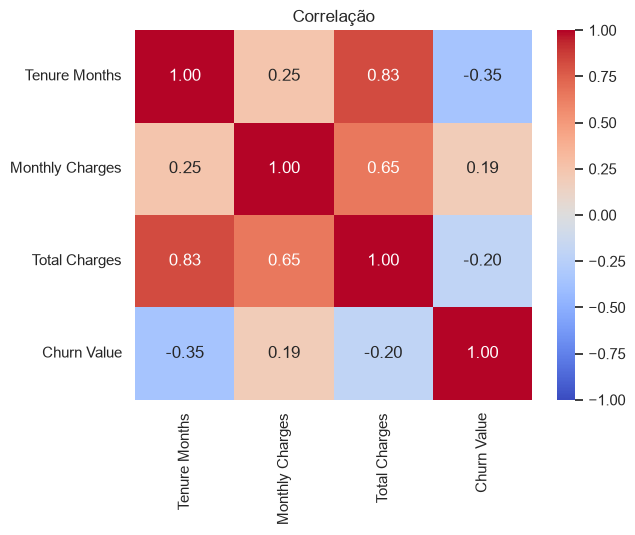

In [21]:
sns.heatmap(df_eda[numericas + ["Churn Value"]].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlação")
plt.show()

**Conclusão:**
- **Tempo de contrato é o sinal mais forte:** mediana de 10 meses entre quem cancela × 38 entre quem fica (correlação −0,35). O churn cai de 53% nos 6 primeiros meses para 10% acima de 4 anos: o risco se concentra no início do relacionamento.
- **Mensalidade mais alta, mais churn:** mediana de 79,65 × 64,43 (correlação 0,19).
- `Total Charges` tem correlação de 0,83 com `Tenure Months` (é aproximadamente tenure × mensalidade). Mantida por enquanto; a regularização dos modelos lida com a redundância.
- Escalas muito diferentes entre as três variáveis: padronizar (`StandardScaler`) para regressão logística e MLP.

## 5. Variáveis categóricas

In [22]:
categoricas = [
    "Gender", "Senior Citizen", "Partner", "Dependents", "Phone Service", "Multiple Lines",
    "Internet Service", "Online Security", "Online Backup", "Device Protection",
    "Tech Support", "Streaming TV", "Streaming Movies", "Contract", "Paperless Billing",
    "Payment Method",
]

for col in categoricas:
    print(df.groupby(col)["Churn Value"].mean().sort_values(ascending=False).round(3), "\n")

Gender
Female    0.269
Male      0.262
Name: Churn Value, dtype: float64 

Senior Citizen
Yes    0.417
No     0.236
Name: Churn Value, dtype: float64 

Partner
No     0.330
Yes    0.197
Name: Churn Value, dtype: float64 

Dependents
No     0.326
Yes    0.065
Name: Churn Value, dtype: float64 

Phone Service
Yes    0.267
No     0.249
Name: Churn Value, dtype: float64 

Multiple Lines
Yes                 0.286
No                  0.250
No phone service    0.249
Name: Churn Value, dtype: float64 

Internet Service
Fiber optic    0.419
DSL            0.190
No             0.074
Name: Churn Value, dtype: float64 

Online Security
No                     0.418
Yes                    0.146
No internet service    0.074
Name: Churn Value, dtype: float64 

Online Backup
No                     0.399
Yes                    0.215
No internet service    0.074
Name: Churn Value, dtype: float64 

Device Protection
No                     0.391
Yes                    0.225
No internet service    0.074
Nam

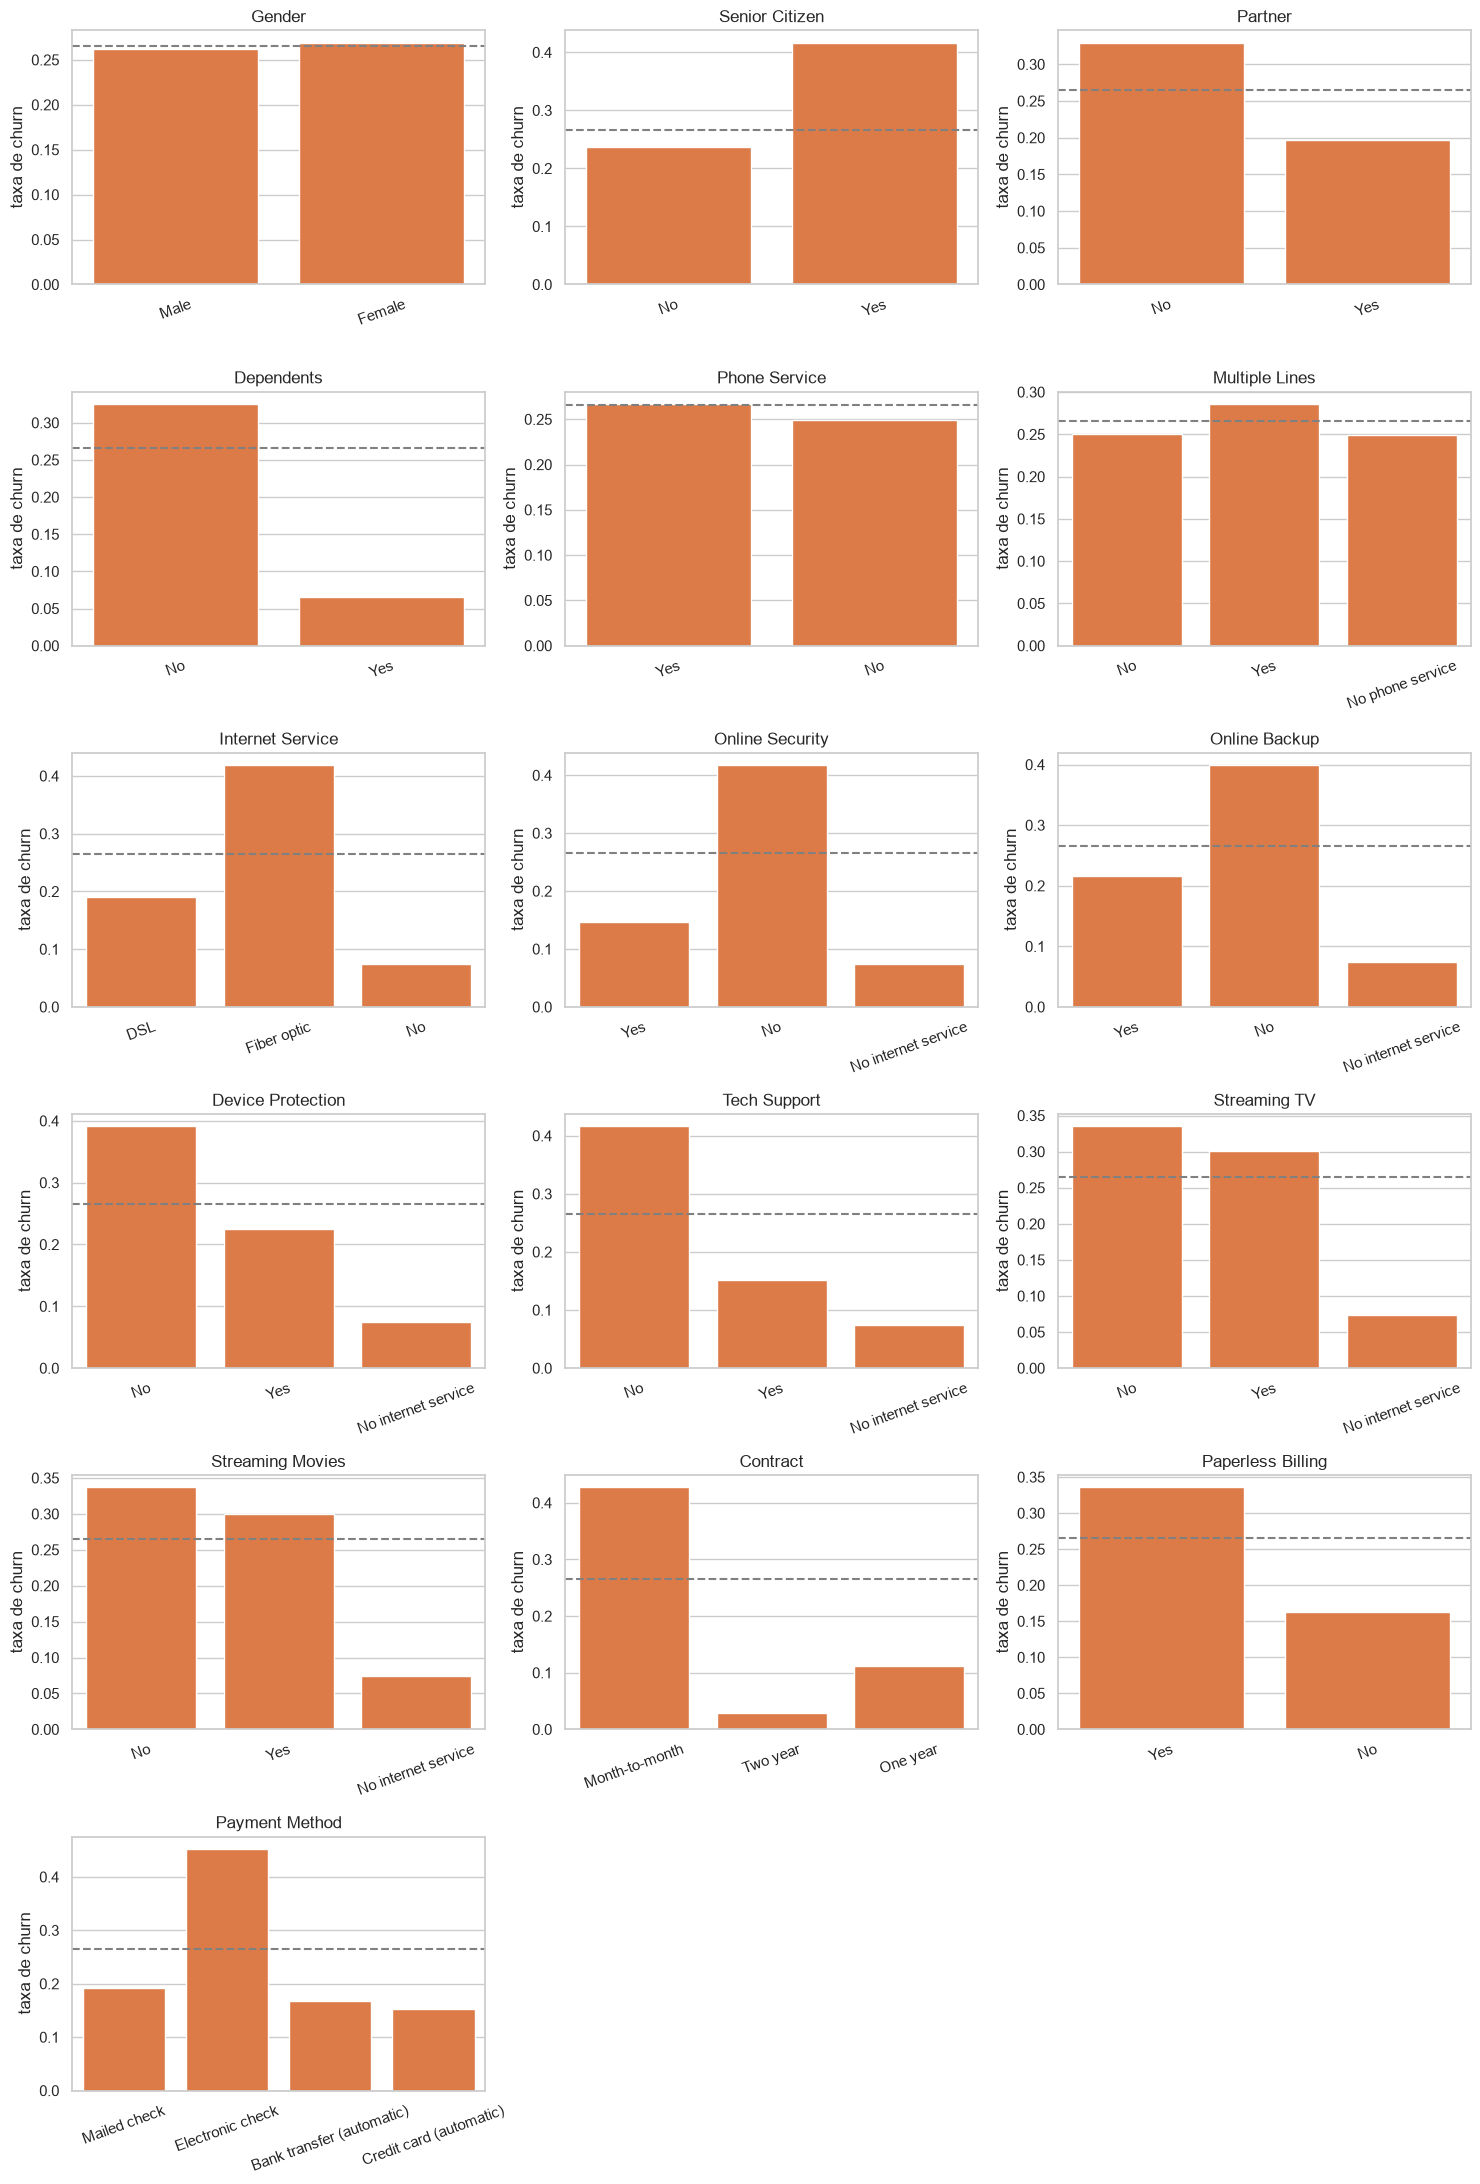

In [23]:
fig, axes = plt.subplots(6, 3, figsize=(15, 22))
for ax, col in zip(axes.flat, categoricas):
    sns.barplot(data=df, x=col, y="Churn Value", color=cores[1], errorbar=None, ax=ax)
    ax.axhline(df["Churn Value"].mean(), color="gray", linestyle="--")
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("taxa de churn")
    ax.tick_params(axis="x", rotation=20)
for ax in axes.flat[len(categoricas):]:
    ax.set_visible(False)
plt.tight_layout()
plt.show()

Combinação de duas variáveis (taxa de churn):

In [24]:
pd.crosstab(df["Contract"], df["Internet Service"], values=df["Churn Value"], aggfunc="mean").round(3)

Internet Service,DSL,Fiber optic,No
Contract,,,
Month-to-month,0.322,0.546,0.189
One year,0.093,0.193,0.025
Two year,0.019,0.072,0.008


**Conclusão:**
- **Contrato é o fator dominante:** mensal 42,7% de churn × 1 ano 11,3% × 2 anos 2,8%. Mensal é 55% da base.
- **Fibra ótica** tem 41,9% de churn × 19,0% no DSL. Combinada com contrato mensal, chega a 54,6% (crosstab).
- Serviços de **proteção e suporte** (Online Security, Tech Support, Online Backup, Device Protection) reduzem o churn: quem não tem fica perto de 40%, quem tem fica entre 15% e 22%. Streaming quase não diferencia.
- **Pagamento por cheque eletrônico** (45,3%) e **fatura digital** (33,6%) estão acima da média; pagamentos automáticos ficam perto de 16%.
- Perfil: idosos (41,7%), sem parceiro (33,0%) e sem dependentes (32,6%) cancelam mais.
- **`Gender` não diferencia** (26,9% F × 26,2% M). Fica fora das features, mas é mantido no dataset para auditar o modelo por grupo (fairness). Remover o atributo não garante, sozinho, um modelo justo.
- `Phone Service` e `Multiple Lines` têm pouco efeito.
- "No internet service" ocorre exatamente quando `Internet Service = "No"`, e "No phone service" quando `Phone Service = "No"`: a informação é redundante. **Regra de limpeza:** quem não tem o serviço base também não tem o adicional, então esses valores viram "No". Não usar -1/0/1, que imporia uma ordem e distâncias sem sentido.

## 6. Colunas de localização

In [25]:
geo = ["Country", "State", "City", "Zip Code", "Lat Long", "Latitude", "Longitude"]
df[geo].nunique()

Country         1
State           1
City         1129
Zip Code     1652
Lat Long     1652
Latitude     1652
Longitude    1651
dtype: int64

In [26]:
df["City"].value_counts().head(10)

City
Los Angeles      305
San Diego        150
San Jose         112
Sacramento       108
San Francisco    104
Fresno            64
Long Beach        60
Oakland           52
Stockton          44
Glendale          40
Name: count, dtype: int64

In [27]:
df["City"].value_counts().describe()

count    1129.000000
mean        6.238264
std        12.254863
min         4.000000
25%         4.000000
50%         4.000000
75%         5.000000
max       305.000000
Name: count, dtype: float64

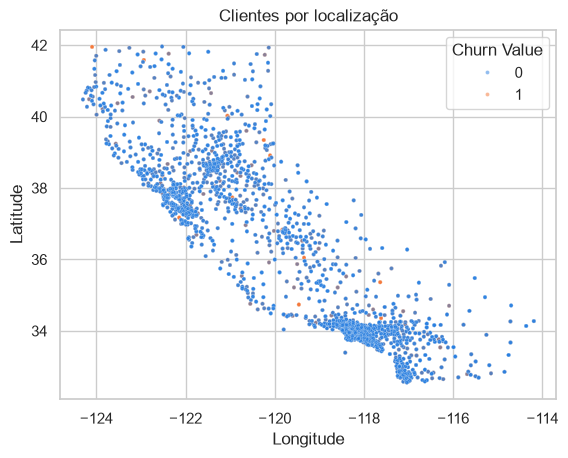

In [28]:
sns.scatterplot(data=df, x="Longitude", y="Latitude", hue="Churn Value", palette=cores,
                s=8, alpha=0.5)
plt.title("Clientes por localização")
plt.show()

**Conclusão:**
- Todos os clientes são da Califórnia (EUA): `Country` e `State` são constantes.
- 1.129 cidades e 1.652 CEPs para 7.043 clientes (mediana de 4 clientes por cidade, cerca de 4 por CEP). O modelo decoraria o local em vez de aprender um padrão.
- `Lat Long` repete `Latitude` e `Longitude`. O mapa não mostra regiões com concentração clara de churn.
- **Decisão:** geografia fora das features nesta fase. Agregar por região fica como melhoria futura.

## 7. Motivos de cancelamento
`Churn Reason` só é preenchida para quem cancelou, então não pode entrar no modelo (vazamento). Serve só para entender o negócio.

In [29]:
df["Churn Reason"].value_counts()

Churn Reason
Attitude of support person                   192
Competitor offered higher download speeds    189
Competitor offered more data                 162
Don't know                                   154
Competitor made better offer                 140
Attitude of service provider                 135
Competitor had better devices                130
Network reliability                          103
Product dissatisfaction                      102
Price too high                                98
Service dissatisfaction                       89
Lack of self-service on Website               88
Extra data charges                            57
Moved                                         53
Limited range of services                     44
Lack of affordable download/upload speed      44
Long distance charges                         44
Poor expertise of phone support               20
Poor expertise of online support              19
Deceased                                       6
Name: c

**Conclusão:**
- 1.869 motivos registrados (um por cliente que cancelou).
- **Concorrência** é o maior grupo: 621 casos (33%) somando oferta, velocidade, dados e aparelhos melhores.
- **Atendimento** vem em seguida: 366 casos (20%) somando atitude do suporte, do prestador e falta de conhecimento técnico.
- Útil para o negócio desenhar a ação de retenção (oferta competitiva, melhoria do atendimento), mas não entra no modelo: só existe depois do cancelamento (vazamento).

## 8. Resumo e decisões para a limpeza

**Regras de limpeza (`clean()`):**
- `Total Charges`: converter para número; `Tenure Months = 0` → 0 (cliente ainda não faturado).
- "No internet service" e "No phone service" → "No" (informação já está em `Internet Service` e `Phone Service`).

**Colunas fora do modelo (e motivo):**
- Vazamento: `Churn Label` (alvo em texto), `Churn Reason` (só existe após o cancelamento), `Churn Score` (saída de outro modelo, correlação 0,66 com o alvo).
- Sem informação: `CustomerID` (identificador), `Count`, `Country`, `State` (constantes).
- Geografia: `City`, `Zip Code`, `Lat Long`, `Latitude`, `Longitude` (alta cardinalidade, risco de decorar).
- Fora de escopo: `CLTV` (estimativa corporativa).
- Sensível: `Gender` (sem sinal; mantido no dataset para auditoria de fairness, junto com `Senior Citizen`).

**Pré-processamento no pipeline (`ColumnTransformer`):**
- Categóricas: um único `OneHotEncoder(drop="if_binary")`. Binárias viram 0/1; `Internet Service`, `Contract` e `Payment Method` viram one-hot.
- Numéricas: imputação (proteção para dados incompletos na API) + `StandardScaler`.

**Principais achados:**
- Churn de 26,5%: classes desbalanceadas, avaliar com AUC-ROC e top 20%.
- O risco se concentra em clientes novos, com contrato mensal, fibra ótica, sem serviços de proteção/suporte e pagando com cheque eletrônico.
- Concorrência e atendimento explicam mais da metade dos cancelamentos.